In [2]:
#import des librairies
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

In [3]:
#import les 3 fichiers

df_asthme = pd.read_csv(
    "../data/raw/Sante/asthme-passages-aux-urgences-et-actes-sos-medecins-dep.csv"
)

df_allergie = pd.read_csv(
    "../data/raw/Sante/allergie-passages-aux-urgences-et-actes-sos-medecins-dep.csv"
    )

df_bronchiolite = pd.read_csv(
    "../data/raw/Sante/bronchiolite-passages-aux-urgences-et-actes-sos-medecins-departement.csv"
)

In [4]:
display(df_asthme.info())
display(df_allergie.info())
display(df_bronchiolite.info())

<class 'pandas.DataFrame'>
RangeIndex: 121200 entries, 0 to 121199
Data columns (total 10 columns):
 #   Column                                                           Non-Null Count   Dtype  
---  ------                                                           --------------   -----  
 0   Semaine                                                          121200 non-null  str    
 1   1er jour de la semaine                                           121200 non-null  str    
 2   Département                                                      121200 non-null  str    
 3   Région                                                           121200 non-null  str    
 4   Classe d'âge                                                     121200 non-null  str    
 5   Taux de passages aux urgences pour asthme                        120700 non-null  float64
 6   Taux d'hospitalisations après passages aux urgences pour asthme  120116 non-null  float64
 7   Taux d'actes médicaux SOS médecins pour 

None

<class 'pandas.DataFrame'>
RangeIndex: 121200 entries, 0 to 121199
Data columns (total 10 columns):
 #   Column                                                             Non-Null Count   Dtype  
---  ------                                                             --------------   -----  
 0   1er jour de la semaine                                             121200 non-null  str    
 1   Semaine                                                            121200 non-null  str    
 2   Département Code                                                   121200 non-null  str    
 3   Département                                                        121200 non-null  str    
 4   Classe d'âge                                                       121200 non-null  str    
 5   Taux de passages aux urgences pour allergie                        120700 non-null  float64
 6   Taux d'hospitalisations après passages aux urgences pour allergie  120116 non-null  float64
 7   Taux d'actes médicaux 

None

<class 'pandas.DataFrame'>
RangeIndex: 36280 entries, 0 to 36279
Data columns (total 10 columns):
 #   Column                                                                 Non-Null Count  Dtype  
---  ------                                                                 --------------  -----  
 0   1er jour de la semaine                                                 36280 non-null  str    
 1   Semaine                                                                36280 non-null  str    
 2   Classe d'âge                                                           36280 non-null  str    
 3   Taux de passages aux urgences pour bronchiolite                        35282 non-null  float64
 4   Taux d'hospitalisations après passages aux urgences pour bronchiolite  32911 non-null  float64
 5   Taux d'actes médicaux SOS médecins pour bronchiolite                   16081 non-null  float64
 6   Département Code                                                       36280 non-null  str    
 7

None

1. Harmoniser le noms des colonnes et les types, ajouter colonne pathologie

In [5]:
#1 - ASTHME
#Harmoniser les noms des colonnes et les types,  ajouter colonne pathologie
dictionnaire_asthme = {"Taux de passages aux urgences pour asthme": "Taux_urgences",
                "Taux d'hospitalisations après passages aux urgences pour asthme": "Taux_hospitalisation", 
                "Taux d'actes médicaux SOS médecins pour asthme" : "Taux_SOS", 
                "Département Code": "code_dept",
                "Semaine" : "date_semaine"
                }

df_asthme = df_asthme.rename(dictionnaire_asthme, axis = 1) 

# Créer la colonne : toutes les lignes reçoivent la valeur "asthme"
df_asthme["pathologie"] = "asthme"

# Vérifier le résultat
display(df_asthme.head())

,date_semaine,1er jour de la semaine,Département,Région,Classe d'âge,Taux_urgences,Taux_hospitalisation,Taux_SOS,code_dept,Région Code,pathologie
0,2026-S40,2026-09-28,Haute-Corse,Corse,65 ans ou plus,318.471338,0.000000,NaN,2B,94,asthme
1,2026-S40,2026-09-28,Gard,Occitanie,15-64 ans,166.805671,270.270270,1869.158878,30,76,asthme
2,2026-S40,2026-09-28,Haute-Garonne,Occitanie,00-14 ans,2232.746955,3875.968992,1041.666667,31,76,asthme
3,2026-S40,2026-09-28,Haute-Garonne,Occitanie,65 ans ou plus,341.296928,357.781753,0.000000,31,76,asthme
4,2026-S40,2026-09-28,Gers,Occitanie,00-14 ans,2777.777778,11111.111111,NaN,32,76,asthme


In [6]:
#2) ALLERGIE
#Harmoniser les noms des colonnes et les types,  ajouter colonne pathologie
dictionnaire_allergie = {"Taux de passages aux urgences pour allergie": "Taux_urgences",
                "Taux d'hospitalisations après passages aux urgences pour allergie": "Taux_hospitalisation", 
                "Taux d'actes médicaux SOS médecins pour allergie" : "Taux_SOS",
                "Département Code": "code_dept",
                "Semaine" : "date_semaine"}

df_allergie = df_allergie.rename(dictionnaire_allergie, axis = 1) 

# Créer la colonne : toutes les lignes reçoivent la valeur "asthme"
df_allergie["pathologie"] = "allergie"

# Vérifier le résultat
display(df_allergie.head())

,1er jour de la semaine,date_semaine,code_dept,Département,Classe d'âge,Taux_urgences,Taux_hospitalisation,Taux_SOS,Région Code,Région,pathologie
0,2026-09-28,2026-S40,23,Creuse,Tous âges,2553.191489,4000.0,NaN,75,Nouvelle Aquitaine,allergie
1,2026-09-28,2026-S40,25,Doubs,Tous âges,489.236791,800.0,760.043431,27,Bourgogne et Franche-Comté,allergie
2,2026-09-28,2026-S40,26,Drôme,65 ans ou plus,300.300300,0.0,NaN,84,Auvergne et Rhône-Alpes,allergie
3,2026-09-28,2026-S40,27,Eure,65 ans ou plus,381.194409,0.0,NaN,28,Normandie,allergie
4,2026-09-28,2026-S40,31,Haute-Garonne,00-14 ans,608.930988,0.0,1041.666667,76,Occitanie,allergie


In [7]:
#2) BRONCHIOLITE
#Harmoniser les noms des colonnes et les types,  ajouter colonne pathologie
dictionnaire_bronchiolite = {"Taux de passages aux urgences pour bronchiolite": "Taux_urgences",
                "Taux d'hospitalisations après passages aux urgences pour bronchiolite": "Taux_hospitalisation", 
                "Taux d'actes médicaux SOS médecins pour bronchiolite" : "Taux_SOS",
                "Département Code": "code_dept",
                "Semaine" : "date_semaine"}

df_bronchiolite = df_bronchiolite.rename(dictionnaire_bronchiolite, axis = 1) 

# Créer la colonne : toutes les lignes reçoivent la valeur "asthme"
df_bronchiolite["pathologie"] = "bronchiolite"

# Vérifier le résultat
display(df_bronchiolite.head())

,1er jour de la semaine,date_semaine,Classe d'âge,Taux_urgences,Taux_hospitalisation,Taux_SOS,code_dept,Département,Région Code,Région,pathologie
0,2026-09-28,2026-S40,0 an,14285.714286,NaN,NaN,09,Ariège,76,Occitanie,bronchiolite
1,2026-09-28,2026-S40,0 an,0.000000,0.000000,NaN,12,Aveyron,76,Occitanie,bronchiolite
2,2026-09-28,2026-S40,0 an,5468.750000,8333.333333,9195.402299,14,Calvados,28,Normandie,bronchiolite
3,2026-09-28,2026-S40,0 an,0.000000,0.000000,NaN,01,Ain,84,Auvergne et Rhône-Alpes,bronchiolite
4,2026-09-28,2026-S40,0 an,7692.307692,0.000000,NaN,05,Hautes-Alpes,93,Provence-Alpes-Côte d'Azur,bronchiolite


2. Concaténer (aligner par colonnes) les trois tables, sans supprimer de données


In [8]:
#Concaténer (aligner par colonnes) les trois tables, sans supprimer de données

df_cible = pd.concat([df_allergie, df_asthme, df_bronchiolite], axis = 0, join = 'outer', ignore_index=True)

#Verification

print(df_cible.shape)
print(df_cible["pathologie"].value_counts())

assert len(df_cible) == (
    len(df_allergie) + len(df_asthme) + len(df_bronchiolite)
)

total = 2*121200 + 36280
print(total)

(278680, 11)


pathologie
allergie        121200
asthme          121200
bronchiolite     36280
Name: count, dtype: int64
278680


In [9]:
#exporter le df_cible as csv
df_cible.to_csv("df_cible.csv", sep=",", index=False)

3. Faire le diagnostic et le nettoyage dans cette base commune
 - creation fiche de travail
 - verification de concatenation (nb des lignes, colonnes, doublons, valeurs manquantes)
 - isoler les legnes contenant 3 taux manquant dans un fichier separé et creation de fichier df_exploitable

In [10]:
#Creation d'un fichier de travail
df_travail = df_cible.copy()


#Verifier si le concatenation a bien conservé les categories d'ages et que les 3 colonnes de taux sont numeriques
taux = ["Taux_urgences", "Taux_hospitalisation", "Taux_SOS"]

print("Dimensions :", df_travail.shape)
display(df_travail.head())
df_travail.info()

# Nombre de lignes par pathologie et classe d'âge
display(
    df_travail.groupby(
        ["pathologie", "Classe d'âge"],
        dropna=False
    ).size().rename("Nombre de lignes").reset_index()
)

Dimensions : (278680, 11)


,1er jour de la semaine,date_semaine,code_dept,Département,Classe d'âge,Taux_urgences,Taux_hospitalisation,Taux_SOS,Région Code,Région,pathologie
0,2026-09-28,2026-S40,23,Creuse,Tous âges,2553.191489,4000.0,NaN,75,Nouvelle Aquitaine,allergie
1,2026-09-28,2026-S40,25,Doubs,Tous âges,489.236791,800.0,760.043431,27,Bourgogne et Franche-Comté,allergie
2,2026-09-28,2026-S40,26,Drôme,65 ans ou plus,300.300300,0.0,NaN,84,Auvergne et Rhône-Alpes,allergie
3,2026-09-28,2026-S40,27,Eure,65 ans ou plus,381.194409,0.0,NaN,28,Normandie,allergie
4,2026-09-28,2026-S40,31,Haute-Garonne,00-14 ans,608.930988,0.0,1041.666667,76,Occitanie,allergie


<class 'pandas.DataFrame'>
RangeIndex: 278680 entries, 0 to 278679
Data columns (total 11 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   1er jour de la semaine  278680 non-null  str    
 1   date_semaine            278680 non-null  str    
 2   code_dept               278680 non-null  str    
 3   Département             278680 non-null  str    
 4   Classe d'âge            278680 non-null  str    
 5   Taux_urgences           276682 non-null  float64
 6   Taux_hospitalisation    273143 non-null  float64
 7   Taux_SOS                125437 non-null  float64
 8   Région Code             278680 non-null  int64  
 9   Région                  278680 non-null  str    
 10  pathologie              278680 non-null  str    
dtypes: float64(3), int64(1), str(7)
memory usage: 23.4 MB


,pathologie,Classe d'âge,Nombre de lignes
0,allergie,00-14 ans,30300
1,allergie,15-64 ans,30300
2,allergie,65 ans ou plus,30300
3,allergie,Tous âges,30300
4,asthme,00-14 ans,30300
5,asthme,15-64 ans,30300
6,asthme,65 ans ou plus,30300
7,asthme,Tous âges,30300
8,bronchiolite,0 an,36280


In [11]:
#Verification des doublons
cles = [
    "pathologie",
    "date_semaine",
    "code_dept",
    "Classe d'âge"
]

# Repérer les identifiants manquants
print("Valeurs manquantes dans la clé :")
display(df_travail[cles].isna().sum())

# Afficher toutes les lignes appartenant à une clé répétée
masque_doublons = df_travail.duplicated(subset=cles, keep=False)

print("Lignes concernées par une clé répétée :", masque_doublons.sum())

display(
    df_travail.loc[masque_doublons]
    .sort_values(cles)
)

Valeurs manquantes dans la clé :


pathologie      0
date_semaine    0
code_dept       0
Classe d'âge    0
dtype: int64

Lignes concernées par une clé répétée : 0


,1er jour de la semaine,date_semaine,code_dept,Département,Classe d'âge,Taux_urgences,Taux_hospitalisation,Taux_SOS,Région Code,Région,pathologie


In [12]:
#Bilan global des taux
bilan_taux = pd.DataFrame({
    "Nombre de NA": df_travail[taux].isna().sum(),
    "Pourcentage de NA": (
        df_travail[taux].isna().mean().mul(100).round(2)
    ),
    "Nombre de zéros": df_travail[taux].eq(0).sum(),
    "Nombre de valeurs négatives": df_travail[taux].lt(0).sum()
})

display(bilan_taux)

,Nombre de NA,Pourcentage de NA,Nombre de zéros,Nombre de valeurs négatives
Taux_urgences,1998,0.72,28428,0
Taux_hospitalisation,5537,1.99,109551,0
Taux_SOS,153243,54.99,15108,0


Les 0 restent des valeurs renseignés, à ne pas supprimer! 

Reperer les lignes avec les valeurs manquantes

In [13]:
#Les lignes avec les taux manquantes
nb_taux_na = df_travail[taux].isna().sum(axis=1)

display(
    nb_taux_na.value_counts()
    .reindex([0, 1, 2, 3], fill_value=0)
    .rename_axis("Nombre de taux manquants")
    .rename("Nombre de lignes")
    .to_frame()
)

,Nombre de lignes
Nombre de taux manquants,
0,124141
1,149128
2,4583
3,828


Il y a 828 lignes avec les 3 taux manquantes, comme attendu (820 + 4 +4)

In [14]:
# Isoler les lignes avec les 3 valeurs manquantes

trois_na = df_travail[taux].isna().all(axis=1)

# Garder une trace des observations sans mesure
df_sans_mesure = df_travail.loc[trois_na].copy()

display(
    df_sans_mesure.groupby("pathologie")
    .size()
    .rename("Lignes avec trois taux NA")
    .to_frame()
)

# Créer un df avec au moins un taux renseigné
df_exploitable = df_travail.loc[~trois_na].copy()

print("Base de référence :", len(df_travail))
print("Lignes sans mesure :", len(df_sans_mesure))
print("Df exploitable :", len(df_exploitable))

,Lignes avec trois taux NA
pathologie,
allergie,4
asthme,4
bronchiolite,820


Base de référence : 278680
Lignes sans mesure : 828
Df exploitable : 277852


In [15]:
#Exporter les 3 fichiers


df_travail.to_csv("df_travail.csv", sep=",", index=False)

df_sans_mesure.to_csv("df_sans_mesure.csv", sep=",", index=False)

df_exploitable.to_csv("df_exploitable.csv", sep=",", index=False)

4. Nettoyage: 
a) Supression des colonnes dont on n'aura pas besoin

In [45]:
# verification des dates

df_exploitable.loc[
    df_exploitable["date_semaine"] == "2021-S01",
    ["date_semaine", "1er jour de la semaine"]
]

,date_semaine,1er jour de la semaine
120796,2021-S01,2021-01-04
120797,2021-S01,2021-01-04
120798,2021-S01,2021-01-04
120799,2021-S01,2021-01-04
120800,2021-S01,2021-01-04
...,...,...
273163,2021-S01,2021-01-04
273164,2021-S01,2021-01-04
273165,2021-S01,2021-01-04
273166,2021-S01,2021-01-04


In [ ]:
#Creation d'un copy 
df_taux_clean = df_exploitable.copy()

#Supresson des colonnes: "1er jour de la semaine", "Département", "Région Code", "Région", "Taux_SOS"
df_taux_clean = df_taux_clean.drop(columns=["1er jour de la semaine", "Département", "Région Code", "Région", "Taux_SOS"])

4. Nettoyage
b) Supprimer les DOM-TOM pour conserver uniquement la France metropolitaine et la Corse 

In [17]:
# Repérer les lignes d’outre-mer
df_outre_mer = (
    df_taux_clean["code_dept"]
    .astype("string")
    .str.startswith("97", na=False)
)

# Vérifier les codes concernés avant suppression
print(
    sorted(
        df_taux_clean.loc[df_outre_mer, "code_dept"]
        .astype("string")
        .unique()
    )
)

print("Nombre de lignes à supprimer :", df_outre_mer.sum())

# Conserver les autres territoires
df_taux_clean = df_taux_clean.loc[df_outre_mer==False].copy()

['971', '972', '973', '974', '976']
Nombre de lignes à supprimer : 13756


4.Nettoyage
c) Supprimer les annees pas retenus, garder 2021 -2024

In [18]:
# Extraire l’année depuis la colonne date_semaine
annees = df_taux_clean["date_semaine"].str[:4].astype(int)

# Garder uniquement les années choisies
df_annees = annees.isin([2021, 2022, 2023, 2024])

df_taux_clean = df_taux_clean.loc[df_annees].copy()

# Vérifier les années restantes
print(sorted(df_taux_clean["date_semaine"].str[:4].unique()))

['2021', '2022', '2023', '2024']


In [19]:
#Verifier si il restent des lignes avec 2 taux NaN
taux_restants = ["Taux_urgences", "Taux_hospitalisation"]

print(
    "Lignes sans aucun taux restant :",
    df_taux_clean[taux_restants].isna().all(axis=1).sum()
)

Lignes sans aucun taux restant : 0


In [20]:
#Verification si doublons n'ont pas ete introduits

cles = [
    "date_semaine",
    "code_dept",
    "pathologie",
    "Classe d'âge"
]

print(
    "Nombre de clés en doublon :",
    df_taux_clean.duplicated(subset=cles).sum()
)

Nombre de clés en doublon : 0


5.
a) Transformation des lignes de la categorie d'ages en colonnes pour le rapprochement avec des autres fichiers sur la base de la "date_semaine" et "code_dept"

In [21]:
#1er tableau avec 18 colonnes taux_classe_dage sans creation des valeurs manqauntes

df_pivot_1 = df_taux_clean.pivot(
    index=["date_semaine", "code_dept"],              #définit une ligne du résultat : une combinaison semaine/département.
    columns=["pathologie", "Classe d'âge"],             #transforme les combinaisons pathologie/âge en colonnes.
    values=["Taux_urgences", "Taux_hospitalisation"]    #indique quelles valeurs placer dans ces colonnes : les deux taux
)

display(df_pivot_1.head())
print("Dimensions :", df_pivot_1.shape)

Taux_urgences                                          \
pathologie                  allergie                                           
Classe d'âge               Tous âges 65 ans ou plus    00-14 ans   15-64 ans   
date_semaine code_dept                                                         
2021-S01     01           446.144041     481.927711   395.256917  443.951165   
             02           719.424460     280.112045  1464.435146  687.022901   
             03           452.898551     232.558140  1562.500000  366.300366   
             04           820.512821     336.700337  2222.222222  736.648250   
             05           618.811881     440.528634     0.000000  858.369099   

                                                                           \
pathologie                  asthme                                          
Classe d'âge             00-14 ans   15-64 ans   Tous âges 65 ans ou plus   
date_semaine code_dept                                                      
2021-S01     01         790.513834  554.938957  446.144041       0.000000   
             02         418.410042    0.000000   79.936051       0.000000   
             03         781.250000  366.300366  362.318841     232.558140   
             04           0.000000  920.810313  615.384615     336.700337   
             05           0.000000  429.184549  247.524752       0.000000   

                                    Taux_hospitalisation                 \
pathologie             bronchiolite             allergie                  
Classe d'âge                   0 an            Tous âges 65 ans ou plus   
date_semaine code_dept                                                    
2021-S01     01         3846.153846             0.000000       0.000000   
             02         4255.319149           581.395349       0.000000   
             03            0.000000           284.900285     408.163265   
             04            0.000000             0.000000       0.000000   
             05            0.000000           546.448087       0.000000   

                                                                         \
pathologie                                          asthme                
Classe d'âge              00-14 ans    15-64 ans 00-14 ans    15-64 ans   
date_semaine code_dept                                                    
2021-S01     01            0.000000     0.000000       0.0   943.396226   
             02         2083.333333  1036.269430       0.0     0.000000   
             03            0.000000     0.000000       0.0     0.000000   
             04            0.000000     0.000000       0.0     0.000000   
             05            0.000000  1315.789474       0.0  1315.789474   

                                                                 
pathologie                                         bronchiolite  
Classe d'âge             Tous âges 65 ans ou plus          0 an  
date_semaine code_dept                                           
2021-S01     01         361.010830            0.0  16666.666667  
             02           0.000000            0.0      0.000000  
             03           0.000000            0.0           NaN  
             04           0.000000            0.0      0.000000  
             05         546.448087            0.0      0.000000

Dimensions : (19968, 18)


In [22]:
#faire un tableau avec 1 niveau de ligne en-tete
# Définir des noms courts dans des dictionnaires pour renommer les en-tetes
noms_ages = {
    "Tous âges": "TousAge",
    "00-14 ans": "0_14",
    "15-64 ans": "15_64",
    "65 ans ou plus": "65plus",
    "0 an": "0an"
}

noms_taux = {
    "Taux_urgences": "urgences",
    "Taux_hospitalisation": "hospitalisation"
}

# Réunir les trois niveaux dans un seul nom
nouveaux_noms = []

for taux, pathologie, age in df_pivot_1.columns:
    age_court = noms_ages[age]
    taux_court = noms_taux[taux]

    nouveau_nom = f"{age_court}_{pathologie}_{taux_court}"

    nouveaux_noms.append(nouveau_nom)

df_pivot_1.columns = nouveaux_noms

# Remettre date_semaine et code_dept en colonnes ordinaires
df_pivot_1 = df_pivot_1.reset_index()

display(df_pivot_1.head())

,date_semaine,code_dept,TousAge_allergie_urgences,65plus_allergie_urgences,0_14_allergie_urgences,15_64_allergie_urgences,0_14_asthme_urgences,15_64_asthme_urgences,TousAge_asthme_urgences,65plus_asthme_urgences,0an_bronchiolite_urgences,TousAge_allergie_hospitalisation,65plus_allergie_hospitalisation,0_14_allergie_hospitalisation,15_64_allergie_hospitalisation,0_14_asthme_hospitalisation,15_64_asthme_hospitalisation,TousAge_asthme_hospitalisation,65plus_asthme_hospitalisation,0an_bronchiolite_hospitalisation
0,2021-S01,01,446.144041,481.927711,395.256917,443.951165,790.513834,554.938957,446.144041,0.000000,3846.153846,0.000000,0.000000,0.000000,0.000000,0.0,943.396226,361.010830,0.0,16666.666667
1,2021-S01,02,719.424460,280.112045,1464.435146,687.022901,418.410042,0.000000,79.936051,0.000000,4255.319149,581.395349,0.000000,2083.333333,1036.269430,0.0,0.000000,0.000000,0.0,0.000000
2,2021-S01,03,452.898551,232.558140,1562.500000,366.300366,781.250000,366.300366,362.318841,232.558140,0.000000,284.900285,408.163265,0.000000,0.000000,0.0,0.000000,0.000000,0.0,NaN
3,2021-S01,04,820.512821,336.700337,2222.222222,736.648250,0.000000,920.810313,615.384615,336.700337,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.000000
4,2021-S01,05,618.811881,440.528634,0.000000,858.369099,0.000000,429.184549,247.524752,0.000000,0.000000,546.448087,0.000000,0.000000,1315.789474,0.0,1315.789474,546.448087,0.0,0.000000


In [36]:
df_pivot_1.info()
df_pivot_1["date_semaine"].sort_values()

df_pivot_1.isna().sum()

df_pivot_1.isna().mean().mul(100)


<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 20 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   date_semaine                      19968 non-null  str    
 1   code_dept                         19968 non-null  str    
 2   TousAge_allergie_urgences         19968 non-null  float64
 3   65plus_allergie_urgences          19968 non-null  float64
 4   0_14_allergie_urgences            19968 non-null  float64
 5   15_64_allergie_urgences           19968 non-null  float64
 6   0_14_asthme_urgences              19968 non-null  float64
 7   15_64_asthme_urgences             19968 non-null  float64
 8   TousAge_asthme_urgences           19968 non-null  float64
 9   65plus_asthme_urgences            19968 non-null  float64
 10  0an_bronchiolite_urgences         19908 non-null  float64
 11  TousAge_allergie_hospitalisation  19892 non-null  float64
 12  65plus_allergie

date_semaine                        0.000000
code_dept                           0.000000
TousAge_allergie_urgences           0.000000
65plus_allergie_urgences            0.000000
0_14_allergie_urgences              0.000000
15_64_allergie_urgences             0.000000
0_14_asthme_urgences                0.000000
15_64_asthme_urgences               0.000000
TousAge_asthme_urgences             0.000000
65plus_asthme_urgences              0.000000
0an_bronchiolite_urgences           0.300481
TousAge_allergie_hospitalisation    0.380609
65plus_allergie_hospitalisation     0.530849
0_14_allergie_hospitalisation       1.272035
15_64_allergie_hospitalisation      0.590946
0_14_asthme_hospitalisation         1.272035
15_64_asthme_hospitalisation        0.590946
TousAge_asthme_hospitalisation      0.380609
65plus_asthme_hospitalisation       0.530849
0an_bronchiolite_hospitalisation    6.685697
dtype: float64

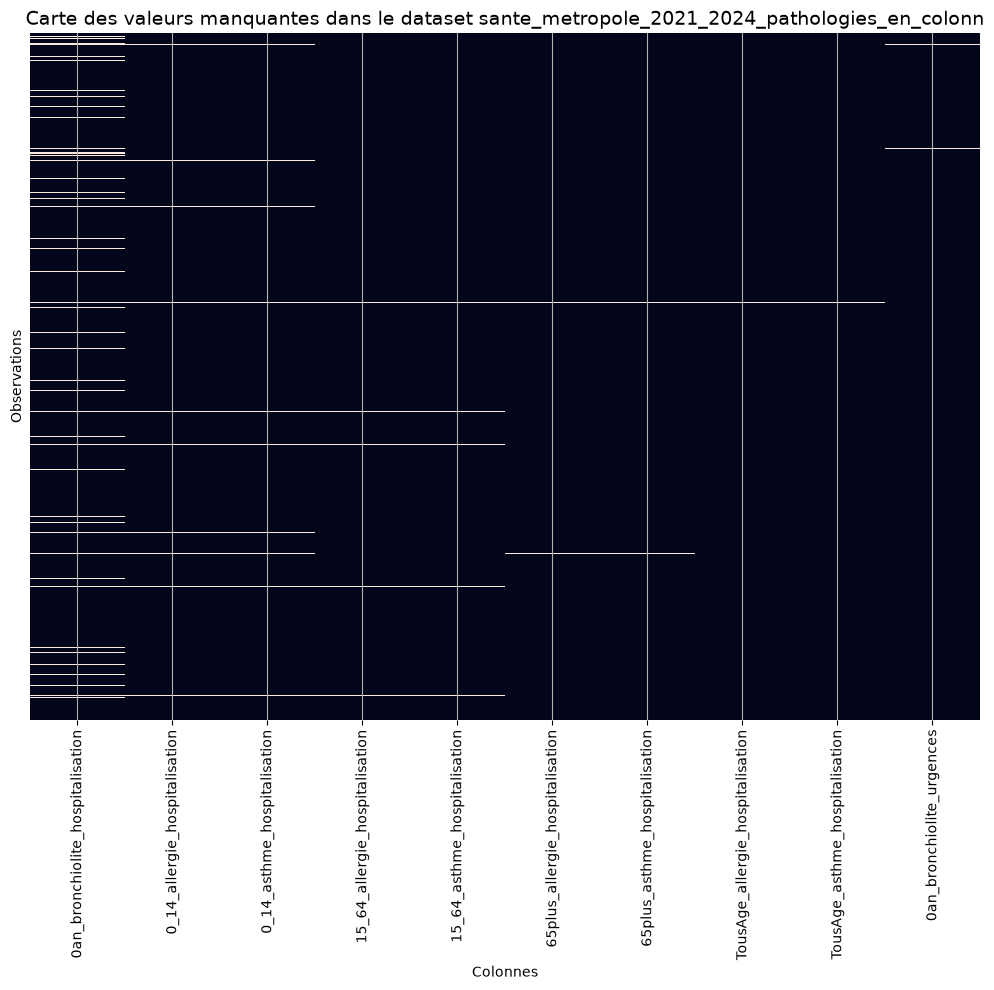

In [37]:
# Affiche le nombre de valeurs manquantes par colonne
missing_values = df_pivot_1.isna().sum()[lambda x: x > 0].sort_values(ascending=False)      #[lambda x: x > 0] → garde uniquement les colonnes qui ont au moins une valeur manquante.


# Visualisation: Heatmap des valeurs manquantes
plt.figure(figsize=(10, 10))
sns.heatmap(df_pivot_1[missing_values.index].isna(), cbar=False, yticklabels=False)
plt.title("Carte des valeurs manquantes dans le dataset sante_metropole_2021_2024_pathologies_en_colonn", fontsize=14)
plt.xlabel("Colonnes")
plt.ylabel("Observations")
plt.tight_layout()
plt.grid(True)
plt.show()


In [41]:
# Afficher les colonnes entièrement vides parmi les taux cibles
colonnes = [
    "TousAge_allergie_urgences", "65plus_allergie_urgences",
    "0_14_allergie_urgences", "15_64_allergie_urgences",
    "0_14_asthme_urgences", "15_64_asthme_urgences",
    "TousAge_asthme_urgences", "65plus_asthme_urgences",
    "0an_bronchiolite_urgences",
    "TousAge_allergie_hospitalisation", "65plus_allergie_hospitalisation",
    "0_14_allergie_hospitalisation", "15_64_allergie_hospitalisation",
    "0_14_asthme_hospitalisation", "15_64_asthme_hospitalisation",
    "TousAge_asthme_hospitalisation", "65plus_asthme_hospitalisation",
    "0an_bronchiolite_hospitalisation",
]

df_cibles = df_pivot_1[colonnes]
display(df_cibles.loc[:, df_cibles.isna().all(axis=0)])

""
0
1
2
3
4
...
19963
19964
19965
19966


In [42]:
# verification des dates

print("Date de début :", df_pivot_1["date_semaine"].min())
print("Date de fin   :", df_pivot_1["date_semaine"].max())

Date de début : 2021-S01
Date de fin   : 2024-S52


19968 lignes

In [23]:
#Exporter le fichier

df_pivot_1.to_csv(
    "sante_metropole_2021_2024_pathologies_en_colonnes.csv",
    index=False,
    )

5.
b) Transformation des lignes de la categorie d'ages en colonnes mais en gardant les pathologies en colonnes (cree des valeurs NA)

In [24]:
#2ieme tableau avec 5*2 colonnes (4 classe par pathologie d'age pour asthme, allergie + 1 pour bronchiolite ) * 2 taux (urgence, hospitalisation)

df_pivot_2 = df_taux_clean.pivot(
    index=["date_semaine", "code_dept", "pathologie"],     #définit une ligne du résultat : une combinaison semaine/département/pathologie.
    columns=["Classe d'âge"],                               #transforme les combinaisons pathologie/âge en colonnes.
    values=["Taux_urgences", "Taux_hospitalisation"]        #indique quelles valeurs placer dans ces colonnes : les deux taux
)

display(df_pivot_2.head())
print("Dimensions :", df_pivot_2.shape)

Taux_urgences                           \
Classe d'âge                                 0 an    00-14 ans   15-64 ans   
date_semaine code_dept pathologie                                            
2021-S01     01        allergie               NaN   395.256917  443.951165   
                       asthme                 NaN   790.513834  554.938957   
                       bronchiolite   3846.153846          NaN         NaN   
             02        allergie               NaN  1464.435146  687.022901   
                       asthme                 NaN   418.410042    0.000000   

                                                                \
Classe d'âge                        65 ans ou plus   Tous âges   
date_semaine code_dept pathologie                                
2021-S01     01        allergie         481.927711  446.144041   
                       asthme             0.000000  446.144041   
                       bronchiolite            NaN         NaN   
             02        allergie         280.112045  719.424460   
                       asthme             0.000000   79.936051   

                                    Taux_hospitalisation               \
Classe d'âge                                        0 an    00-14 ans   
date_semaine code_dept pathologie                                       
2021-S01     01        allergie                      NaN     0.000000   
                       asthme                        NaN     0.000000   
                       bronchiolite         16666.666667          NaN   
             02        allergie                      NaN  2083.333333   
                       asthme                        NaN     0.000000   

                                                                             
Classe d'âge                           15-64 ans 65 ans ou plus   Tous âges  
date_semaine code_dept pathologie                                            
2021-S01     01        allergie         0.000000            0.0    0.000000  
                       asthme         943.396226            0.0  361.010830  
                       bronchiolite          NaN            NaN         NaN  
             02        allergie      1036.269430            0.0  581.395349  
                       asthme           0.000000            0.0    0.000000

Dimensions : (59844, 10)


In [25]:
#faire un tableau avec 1 niveau de ligne en-tete
# Définir des noms courts dans des dictionnaires pour renommer les en-tetes
noms_ages = {
    "Tous âges": "TousAge",
    "00-14 ans": "0_14",
    "15-64 ans": "15_64",
    "65 ans ou plus": "65plus",
    "0 an": "0an"
}

noms_taux = {
    "Taux_urgences": "urgences",
    "Taux_hospitalisation": "hospitalisation"
}

# Réunir les deux niveaux dans un seul nom
nouveaux_noms2 = []

for taux, age in df_pivot_2.columns:
    age_court = noms_ages[age]
    taux_court = noms_taux[taux]

    nouveau_nom2 = f"{age_court}_{taux_court}"

    nouveaux_noms2.append(nouveau_nom2)

df_pivot_2.columns = nouveaux_noms2

# Remettre date_semaine et code_dept en colonnes ordinaires
df_pivot_2 = df_pivot_2.reset_index()

display(df_pivot_2.head())

,date_semaine,code_dept,pathologie,0an_urgences,0_14_urgences,15_64_urgences,65plus_urgences,TousAge_urgences,0an_hospitalisation,0_14_hospitalisation,15_64_hospitalisation,65plus_hospitalisation,TousAge_hospitalisation
0,2021-S01,01,allergie,NaN,395.256917,443.951165,481.927711,446.144041,NaN,0.000000,0.000000,0.0,0.000000
1,2021-S01,01,asthme,NaN,790.513834,554.938957,0.000000,446.144041,NaN,0.000000,943.396226,0.0,361.010830
2,2021-S01,01,bronchiolite,3846.153846,NaN,NaN,NaN,NaN,16666.666667,NaN,NaN,NaN,NaN
3,2021-S01,02,allergie,NaN,1464.435146,687.022901,280.112045,719.424460,NaN,2083.333333,1036.269430,0.0,581.395349
4,2021-S01,02,asthme,NaN,418.410042,0.000000,0.000000,79.936051,NaN,0.000000,0.000000,0.0,0.000000


In [26]:
#Exporter le fichier 2

df_pivot_2.to_csv(
    "sante_metropole_2021_2024_pathologies_en_lignes.csv",
    index=False,
    )

Quelques graphiques

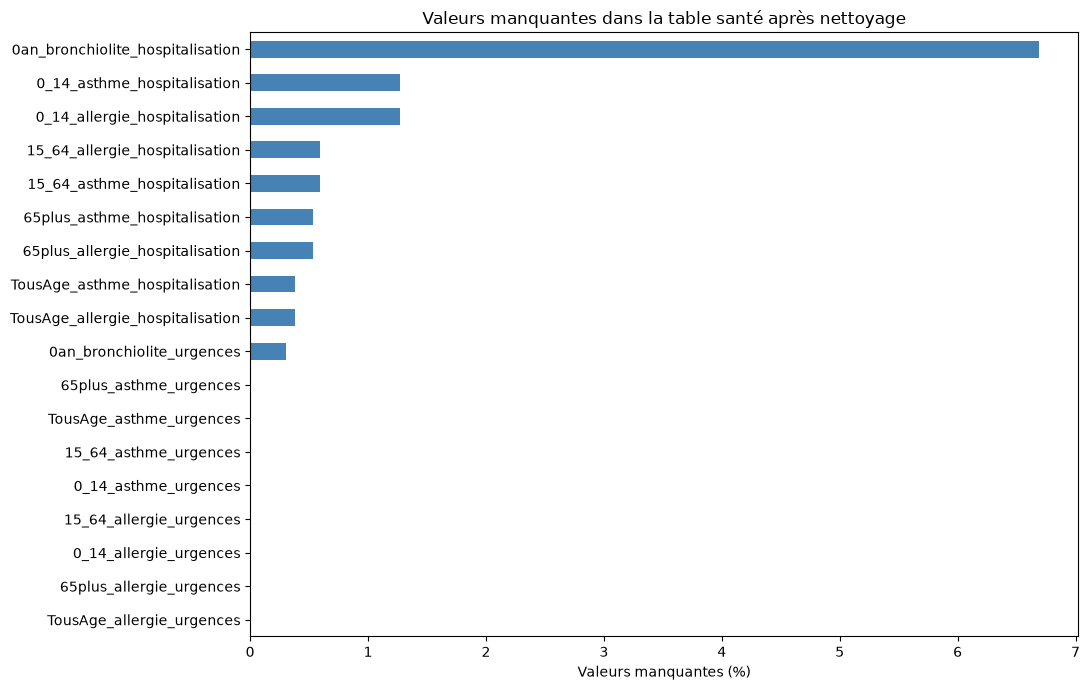

In [31]:
#Valeurs manquantes apres le pivot


# Sélectionner uniquement les colonnes de taux
colonnes_taux = [
    col for col in df_pivot_1.columns
    if col not in ["date_semaine", "code_dept"]
]

pourcentage_na = (
    df_pivot_1[colonnes_taux]
    .isna()
    .mean()
    .mul(100)
    .sort_values()
)

pourcentage_na.plot.barh(figsize=(11, 7), color="steelblue")

plt.title("Valeurs manquantes dans la table santé après nettoyage")
plt.xlabel("Valeurs manquantes (%)")
plt.ylabel("")
plt.tight_layout()
plt.show()

Les évolutions hebdomadaires des urgences
On conserve « Tous âges » pour l’asthme et l’allergie, et « 0 an » pour la bronchiolite. Chaque courbe représente la médiane des taux départementaux disponibles, pas un taux national.

Les trois panneaux ont des échelles distinctes et concernent des populations différentes. Si le nombre de départements renseignés varie, cela peut aussi influencer la courbe.

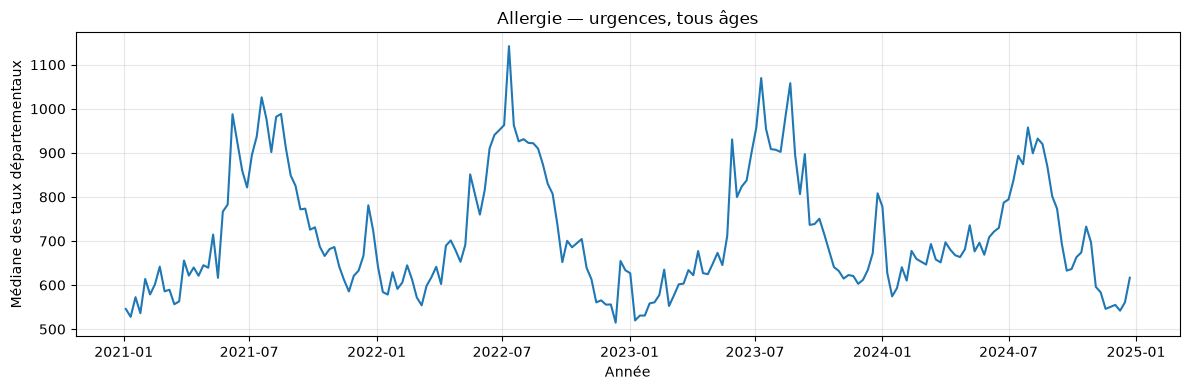

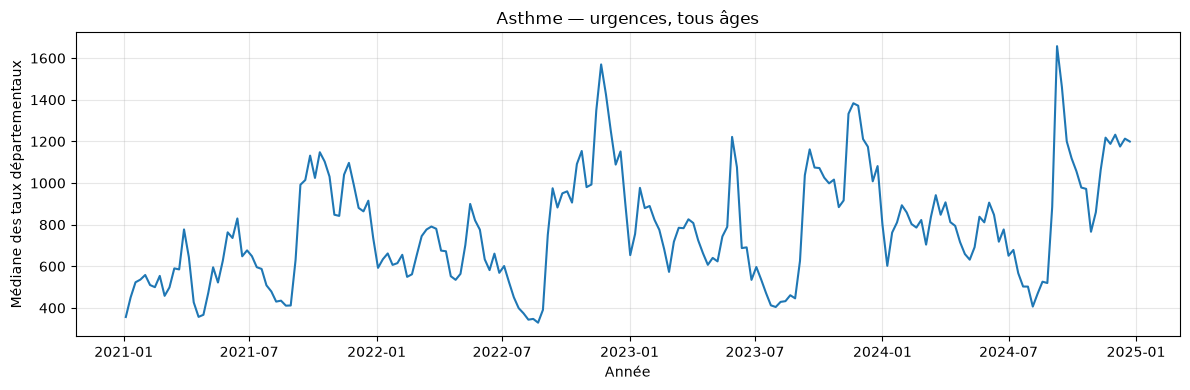

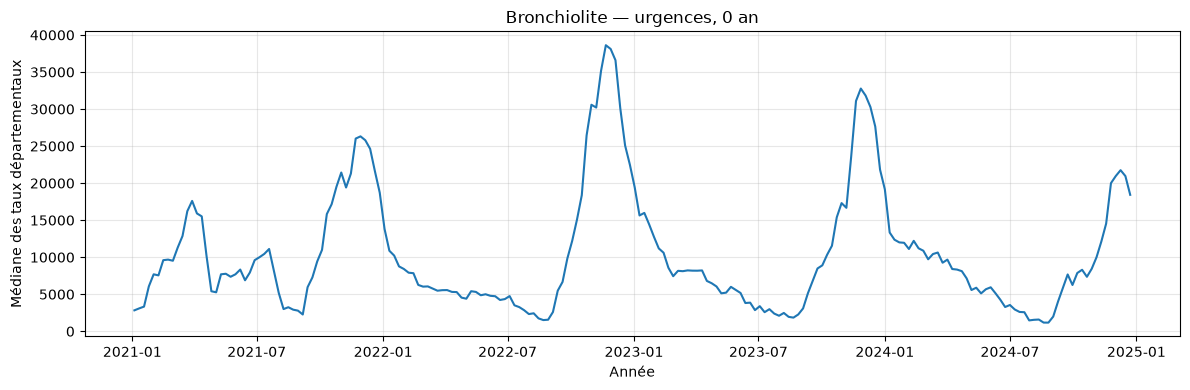

In [28]:
colonnes = [
    "TousAge_allergie_urgences",
    "TousAge_asthme_urgences",
    "0an_bronchiolite_urgences"
]

mediane_semaine = (
    df_pivot_1.groupby("date_semaine")[colonnes]
    .median()
    .sort_index()
)

# Transformer les semaines en dates uniquement pour le graphique
dates = pd.to_datetime(
    mediane_semaine.index + "-1",
    format="%G-S%V-%u"
)

plt.figure(figsize=(12, 4))
plt.plot(dates, mediane_semaine["TousAge_allergie_urgences"])

plt.title("Allergie — urgences, tous âges")
plt.xlabel("Année")
plt.ylabel("Médiane des taux départementaux")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(dates, mediane_semaine["TousAge_asthme_urgences"])

plt.title("Asthme — urgences, tous âges")
plt.xlabel("Année")
plt.ylabel("Médiane des taux départementaux")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(dates, mediane_semaine["0an_bronchiolite_urgences"])

plt.title("Bronchiolite — urgences, 0 an")
plt.xlabel("Année")
plt.ylabel("Médiane des taux départementaux")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

3. Les corrélations entre les taux



In [29]:
colonnes_correlation = []

for colonne in df_pivot_1.columns:
    if colonne not in ["date_semaine", "code_dept"]:
        if "TousAge" not in colonne:
            colonnes_correlation.append(colonne)

# Vérifier la sélection : 14 colonnes attendues
print(colonnes_correlation)
print("Nombre de colonnes :", len(colonnes_correlation))

['65plus_allergie_urgences', '0_14_allergie_urgences', '15_64_allergie_urgences', '0_14_asthme_urgences', '15_64_asthme_urgences', '65plus_asthme_urgences', '0an_bronchiolite_urgences', '65plus_allergie_hospitalisation', '0_14_allergie_hospitalisation', '15_64_allergie_hospitalisation', '0_14_asthme_hospitalisation', '15_64_asthme_hospitalisation', '65plus_asthme_hospitalisation', '0an_bronchiolite_hospitalisation']
Nombre de colonnes : 14


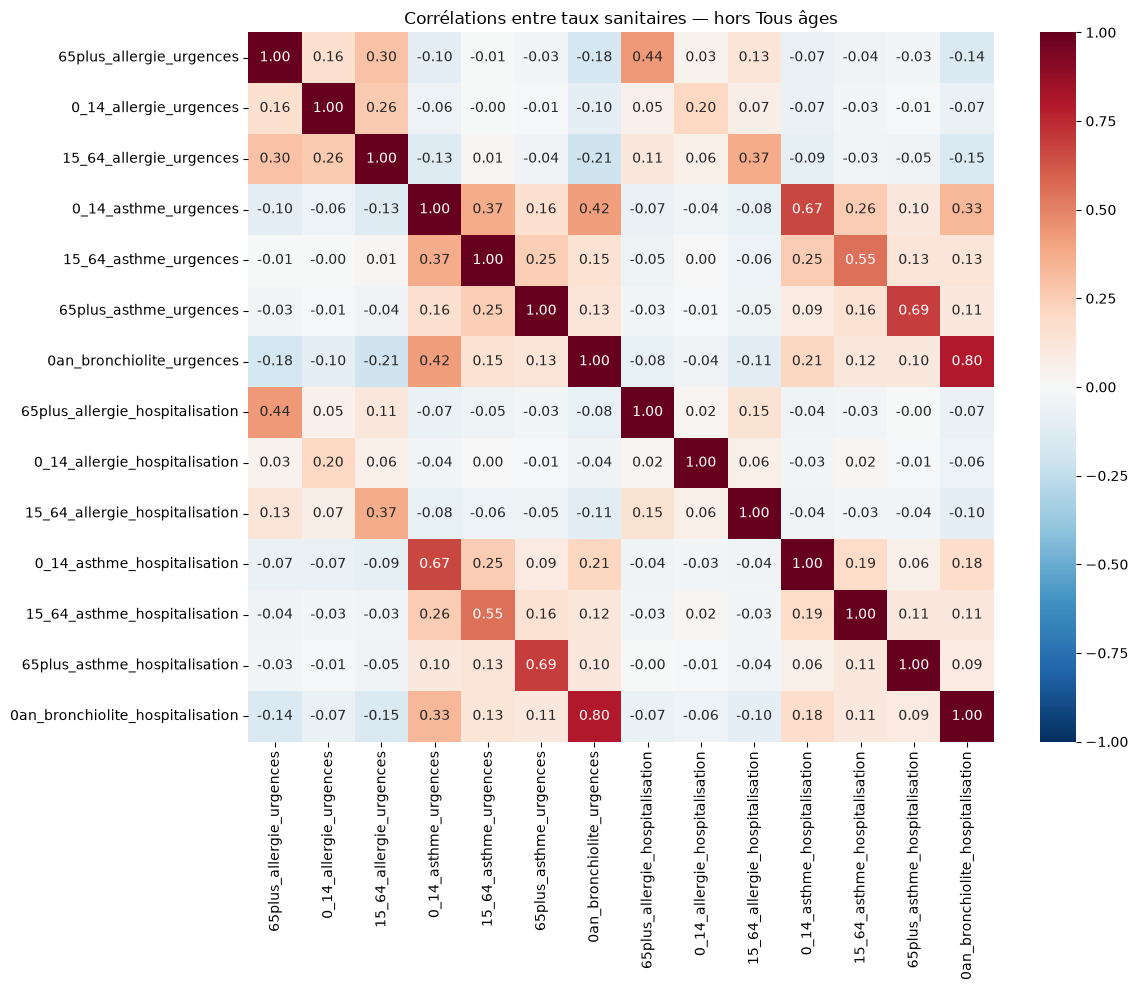

In [30]:
correlations = df_pivot_1[colonnes_correlation].corr()

plt.figure(figsize=(12, 10))

sns.heatmap(
    correlations,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f"
)

plt.title("Corrélations entre taux sanitaires — hors Tous âges")
plt.tight_layout()
plt.show()